In [2]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

In [3]:
# Simulate a dataset for an Airbnb data analysis scenario
np.random.seed(42)  # Set seed for reproducibility

# Generate simulated data
n_samples = 200
data = {
    "listing_id": np.arange(1, n_samples + 1),
    "price_per_night": np.random.uniform(50, 500, n_samples),
    "number_of_reviews": np.random.poisson(15, n_samples),
    "rating": np.random.uniform(3.0, 5.0, n_samples),
    "availability_30": np.random.randint(0, 31, n_samples),
    "host_response_time": np.random.choice(["within an hour", "within a day", "a few days or more"], n_samples),
    "is_superhost": np.random.choice([1, 0], n_samples, p=[0.3, 0.7]),
}

# Convert to a DataFrame
df = pd.DataFrame(data)

# Add a dependent variable for regression analysis (e.g., popularity score)
# Assume popularity_score is influenced by price, reviews, rating, and availability
df["popularity_score"] = (
    0.3 * df["price_per_night"]
    + 0.5 * df["number_of_reviews"]
    + 2 * df["rating"]
    + 1.5 * df["availability_30"]
    + np.random.normal(0, 10, n_samples)  # Noise
)



In [4]:
print(df.shape)

df.head()

(200, 8)


,listing_id,price_per_night,number_of_reviews,rating,availability_30,host_response_time,is_superhost,popularity_score
0,1,218.543053,17,4.661239,11,within a day,1,130.934068
1,2,477.821438,16,4.930054,2,a few days or more,1,167.680565
2,3,379.397274,9,3.248594,19,within an hour,0,179.252086
3,4,319.396318,15,4.461735,25,a few days or more,1,153.864549
4,5,120.208388,17,4.876681,21,within an hour,0,84.987369


In [5]:
df.isnull().sum()

listing_id            0
price_per_night       0
number_of_reviews     0
rating                0
availability_30       0
host_response_time    0
is_superhost          0
popularity_score      0
dtype: int64

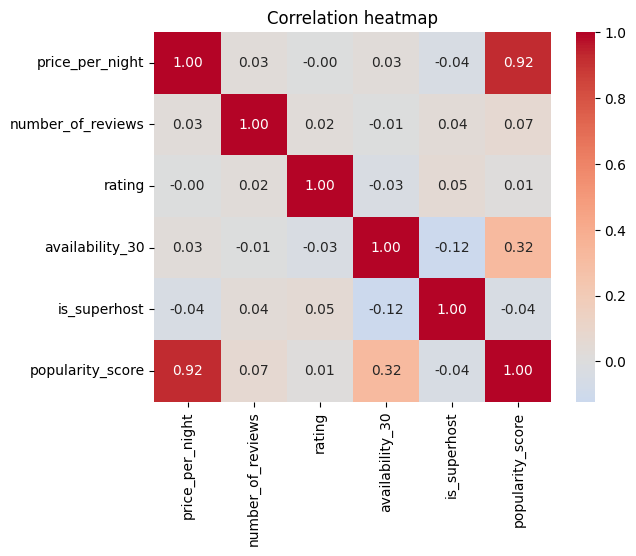

In [6]:
# host_response_time is categorical, so restrict the correlation matrix to numeric columns
sns.heatmap(
    df.drop(columns=["listing_id"]).corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
)
plt.title("Correlation heatmap")
plt.show()

In [7]:
X = df[["price_per_night", "number_of_reviews", "rating", "availability_30"]]
X = sm.add_constant(X)
y = df["popularity_score"]

# OLS is the right model here because popularity_score is continuous.
# Logit would require a binary outcome (see the last cell).
model = sm.OLS(y, X).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:       popularity_score   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.934
Method:                 Least Squares   F-statistic:                     709.0
Date:                Thu, 10 Sep 2026   Prob (F-statistic):          6.17e-115
Time:                        19:59:00   Log-Likelihood:                -758.29
No. Observations:                 200   AIC:                             1527.
Df Residuals:                     195   BIC:                             1543.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const                 6.1895      6.36

In [8]:
## Post regression
# 1.  Residual Analysis # Plot residuals vs. fitted values, Q-Q plot to check for normality
# 2. Multicollinearity Check #VIF>10 indicates high multicollinearity.
# 3. Evaluate Model Fit
# 4. Outlier Detection # Cook's distance
# 5. Transformation and Interaction Terms

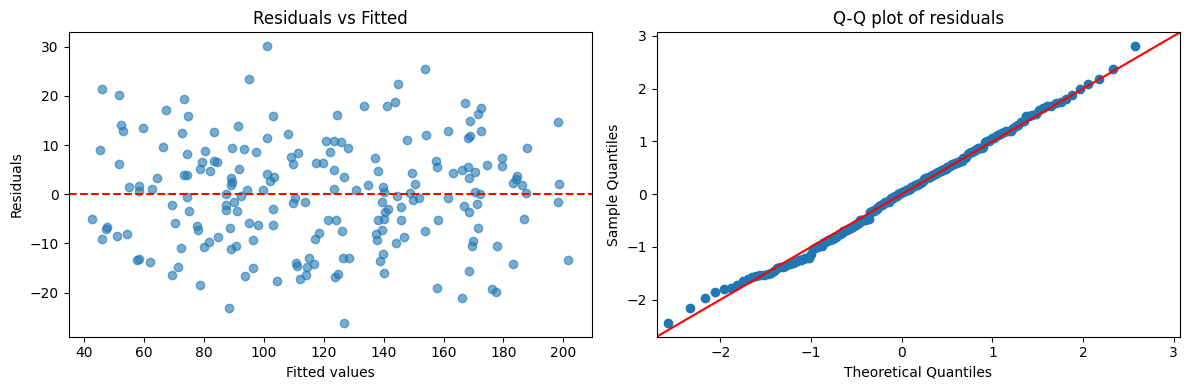

R-squared: 0.936
Adj. R-squared: 0.934
AIC: 1526.6
BIC: 1543.1
Cook's distance threshold (4/n): 0.0200
Potential influential observations: 12


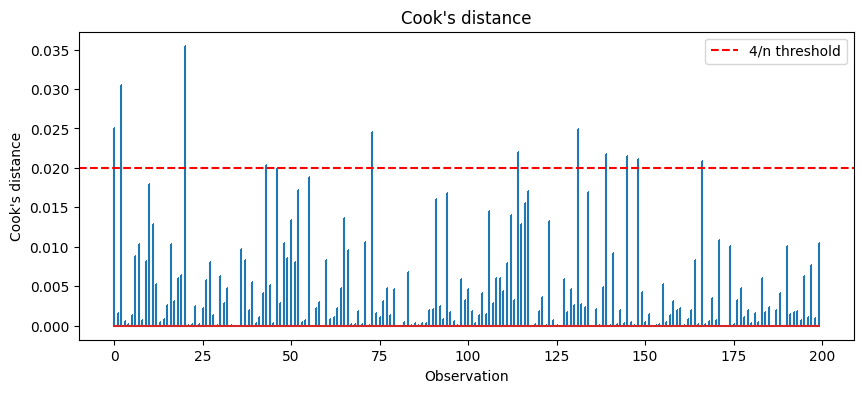

In [9]:
# 1. Residual analysis: residuals vs fitted, and a Q-Q plot
fitted = model.fittedvalues
resid = model.resid

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fitted, resid, alpha=0.6)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Fitted values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residuals vs Fitted")

sm.qqplot(resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("Q-Q plot of residuals")
plt.tight_layout()
plt.show()

# 3. Model fit
print("R-squared:", round(model.rsquared, 3))
print("Adj. R-squared:", round(model.rsquared_adj, 3))
print("AIC:", round(model.aic, 1))
print("BIC:", round(model.bic, 1))

# 4. Outlier detection: Cook's distance
influence = model.get_influence()
cooks_d = influence.cooks_distance[0]
threshold = 4 / len(df)
n_influential = int((cooks_d > threshold).sum())
print(f"Cook's distance threshold (4/n): {threshold:.4f}")
print(f"Potential influential observations: {n_influential}")

plt.figure(figsize=(10, 4))
plt.stem(np.arange(len(cooks_d)), cooks_d, markerfmt=",")
plt.axhline(threshold, color="red", linestyle="--", label="4/n threshold")
plt.xlabel("Observation")
plt.ylabel("Cook's distance")
plt.title("Cook's distance")
plt.legend()
plt.show()

In [10]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

X = df[['price_per_night', 'rating', 'availability_30']]
X = sm.add_constant(X)
vif_data = pd.DataFrame()
vif_data['Feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print(vif_data)

           Feature        VIF
0            const  57.542461
1  price_per_night   1.000760
2           rating   1.001145
3  availability_30   1.001905


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
)

# Logistic regression needs a 0/1 outcome, not the continuous popularity_score.
X_logit = df[["price_per_night", "number_of_reviews", "rating", "availability_30"]]
y_logit = df["is_superhost"]

X_train, X_test, y_train, y_test = train_test_split(
    X_logit, y_logit, test_size=0.3, random_state=42
)

logreg = LogisticRegression(max_iter=1000).fit(X_train, y_train)

y_pred = logreg.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 3))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 3))
print("F1:", round(f1_score(y_test, y_pred, zero_division=0), 3))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))


Accuracy: 0.683
Precision: 0.0
Recall: 0.0
F1: 0.0
Confusion matrix:
 [[41  0]
 [19  0]]
